# FinSignal · Pipeline 2: Corporate Event Classification (Fine-tuning)
**ISOM5240 Group 7** · Company: **Wealthsimple** (https://www.wealthsimple.com/)

**Objective.** Fine-tune `distilbert-base-uncased` to classify financial news into the **7 corporate event categories of the project proposal**, the second pipeline of the FinSignal app for Wealthsimple.

**Notebook flow**
1. Setup (pinned libraries, seed, GPU check)
2. Load dataset from Hugging Face
3. Pre-processing: cleaning, label mapping, de-duplication, leakage removal, stratified split
4. Exploratory checks (class balance, token lengths)
5. Tokenisation
6. Fine-tuning with the Hugging Face `Trainer`
7. Evaluation on the held-out test set (accuracy, per-class report, confusion matrix, runtime)
8. Save / publish the fine-tuned model and the dataset files


## 1. Setup

In [1]:
# library versions (identical to the deployed Streamlit app's requirements.txt)
!pip -q install "transformers==4.57.1" "datasets==3.6.0" "accelerate==1.10.1" "huggingface_hub>=0.34,<1.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 62.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 74.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompa

In [2]:
import os, json, time, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
import transformers
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer,
                          pipeline, set_seed)

SEED = 42
set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("transformers", transformers.__version__, "| torch", torch.__version__, "| device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

transformers 4.57.1 | torch 2.11.0+cu130 | device: cuda
GPU: Tesla T4


In [3]:
# ---------------- configuration ----------------
HF_USERNAME   = "Ikenna14"            # <- Hugging Face account that hosts the models
BASE_MODEL    = "distilbert-base-uncased"    # pre-trained checkpoint from Hugging Face
DATASET_ID    = "zeroshot/twitter-financial-news-topic"
HUB_MODEL_ID  = f"{HF_USERNAME}/finsignal-event-distilbert"
OUTPUT_DIR    = "finsignal-event-distilbert"
DATA_DIR      = "data"
MAX_LEN       = 96       # covers >99% of headlines (checked in section 4)
LEARNING_RATE = 3e-5
EPOCHS        = 4
BATCH_SIZE    = 32
PUSH_TO_HUB   = True
os.makedirs(DATA_DIR, exist_ok=True)

## 2. Load the dataset

In [4]:
raw = load_dataset(DATASET_ID)
print(raw)
train_raw = raw["train"].to_pandas()
test_raw = raw["validation"].to_pandas()   # official held-out split -> our TEST set
train_raw.head()

README.md: 0.00B [00:00, ?B/s]

topic_train.csv: 0.00B [00:00, ?B/s]

topic_valid.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/16990 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/4117 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16990
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 4117
    })
})


,text,label
0,Here are Thursday's biggest analyst calls: App...,0
1,Buy Las Vegas Sands as travel to Singapore bui...,0
2,"Piper Sandler downgrades DocuSign to sell, cit...",0
3,"Analysts react to Tesla's latest earnings, bre...",0
4,Netflix and its peers are set for a ‘return to...,0


## 3. Pre-processing

**3.1 Text cleaning** — the same function is reused inside the Streamlit app, so training and inference text match exactly.

In [5]:
import html, re

_URL_RE = re.compile(r"https?://\S+|www\.\S+")
_WS_RE = re.compile(r"\s+")

def clean_text(text):
    """Unescape HTML entities (&amp; -> &), remove URLs, normalise whitespace.
    The exact same function is used in the Streamlit app (utils.py)."""
    if text is None:
        return ""
    text = html.unescape(str(text))
    text = _URL_RE.sub(" ", text)
    return _WS_RE.sub(" ", text).strip()

print(clean_text("Fed hikes rates by 25bp &amp; signals pause https://t.co/abc123  "))

Fed hikes rates by 25bp & signals pause


**3.2 Label definitions**

In [6]:
# Original 20 topic labels of zeroshot/twitter-financial-news-topic (from the dataset card)
TOPIC_NAMES = {
    0: "Analyst Update", 1: "Fed | Central Banks", 2: "Company | Product News",
    3: "Treasuries | Corporate Debt", 4: "Dividend", 5: "Earnings", 6: "Energy | Oil",
    7: "Financials", 8: "Currencies", 9: "General News | Opinion",
    10: "Gold | Metals | Materials", 11: "IPO", 12: "Legal | Regulation",
    13: "M&A | Investments", 14: "Macro", 15: "Markets", 16: "Politics",
    17: "Personnel Change", 18: "Stock Commentary", 19: "Stock Movement",
}

# Project event taxonomy = the 7 corporate event categories in the approved proposal
EVENT_LABELS = ["Earnings & Guidance", "Mergers & Acquisitions", "Regulatory & Legal", "Financing",
                "Management Change", "Product & Business Expansion", "Other"]

# Rule: map a source topic to an event only when the topic is company-specific and matches the
# event definition; everything else (macro, markets, commentary, analyst calls, dividends) -> Other.
TOPIC_TO_EVENT = {
    5: "Earnings & Guidance",
    13: "Mergers & Acquisitions",
    12: "Regulatory & Legal",
    3: "Financing", 11: "Financing",          # corporate debt, IPOs
    17: "Management Change",
    2: "Product & Business Expansion",
    0: "Other", 1: "Other", 4: "Other", 6: "Other", 7: "Other", 8: "Other", 9: "Other",
    10: "Other", 14: "Other", 15: "Other", 16: "Other", 18: "Other", 19: "Other",
}
assert set(TOPIC_TO_EVENT) == set(range(20)) and set(TOPIC_TO_EVENT.values()) == set(EVENT_LABELS)

EVENT_ID2LABEL = dict(enumerate(EVENT_LABELS))
EVENT_LABEL2ID = {v: k for k, v in EVENT_ID2LABEL.items()}
pd.DataFrame({"original_topic": TOPIC_NAMES.values(),
              "project_event": [TOPIC_TO_EVENT[i] for i in TOPIC_NAMES]})

,original_topic,project_event
0,Analyst Update,Other
1,Fed | Central Banks,Other
2,Company | Product News,Product & Business Expansion
3,Treasuries | Corporate Debt,Financing
4,Dividend,Other
5,Earnings,Earnings & Guidance
6,Energy | Oil,Other
7,Financials,Other
8,Currencies,Other
9,General News | Opinion,Other


**3.3 Clean, map labels, remove empty rows and duplicates, and remove any training text that also appears in the test set (prevents leakage).**

In [7]:
def prepare(df):
    out = pd.DataFrame({"text": df["text"].map(clean_text),
                        "label_name": df["label"].map(lambda y: TOPIC_TO_EVENT[int(y)])})
    out = out[out["text"].str.len() > 0]
    return out.drop_duplicates(subset="text").reset_index(drop=True)

train_all = prepare(train_raw)
test_df = prepare(test_raw)
before = len(train_all)
train_all = train_all[~train_all["text"].isin(set(test_df["text"]))].reset_index(drop=True)

print(f"train raw: {len(train_raw)} -> cleaned: {before} -> after leakage removal: {len(train_all)}")
print(f"test  raw: {len(test_raw)} -> cleaned: {len(test_df)}")

for d in (train_all, test_df):
    d["label"] = d["label_name"].map(EVENT_LABEL2ID).astype(int)

train raw: 16990 -> cleaned: 15359 -> after leakage removal: 14784
test  raw: 4117 -> cleaned: 3972


**3.4 Stratified train / validation split** (90% / 10% of the training data). The test set is never used for training or model selection inside this notebook.

In [8]:
train_df, val_df = train_test_split(train_all, test_size=0.10, stratify=train_all["label"],
                                    random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)

split_sizes = pd.DataFrame({"split": ["train", "validation", "test"],
                            "samples": [len(train_df), len(val_df), len(test_df)]})
split_sizes

,split,samples
0,train,13305
1,validation,1479
2,test,3972


## 4. Exploratory checks

,train,validation,test
label_name,,,
Earnings & Guidance,876,98,242
Mergers & Acquisitions,406,45,116
Regulatory & Legal,389,43,115
Financing,242,27,86
Management Change,423,47,111
Product & Business Expansion,2891,321,831
Other,8078,898,2471


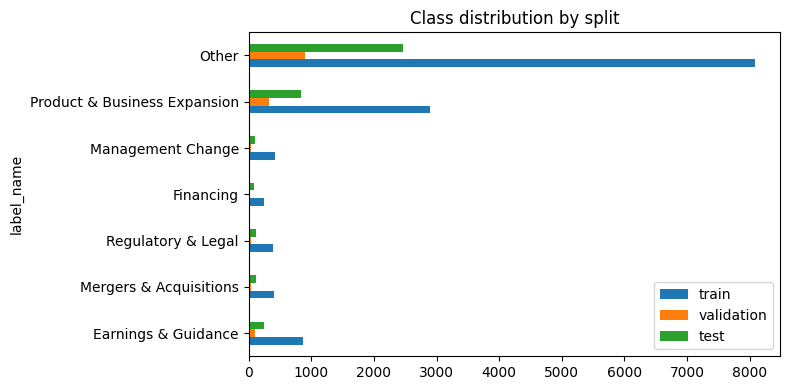

In [9]:
dist = pd.concat({"train": train_df["label_name"].value_counts(),
                  "validation": val_df["label_name"].value_counts(),
                  "test": test_df["label_name"].value_counts()}, axis=1).loc[EVENT_LABELS]
display(dist)
dist.plot.barh(figsize=(8, 4), title="Class distribution by split"); plt.tight_layout(); plt.show()

In [10]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
lengths = [len(x) for x in tokenizer(train_df["text"].tolist(), truncation=False)["input_ids"]]
print(f"token length  mean={np.mean(lengths):.1f}  p95={np.percentile(lengths, 95):.0f}  "
      f"p99={np.percentile(lengths, 99):.0f}  max={max(lengths)}")
print(f"share of samples <= MAX_LEN ({MAX_LEN}): {np.mean(np.array(lengths) <= MAX_LEN):.2%}")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

token length  mean=26.6  p95=50  p99=71  max=138
share of samples <= MAX_LEN (96): 99.73%


## 5. Tokenisation

In [11]:
def to_hf(df):
    return Dataset.from_pandas(df[["text", "label"]], preserve_index=False)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

train_ds = to_hf(train_df).map(tokenize, batched=True)
val_ds = to_hf(val_df).map(tokenize, batched=True)
test_ds = to_hf(test_df).map(tokenize, batched=True)
collator = DataCollatorWithPadding(tokenizer=tokenizer)
train_ds

Map:   0%|          | 0/13305 [00:00<?, ? examples/s]

Map:   0%|          | 0/1479 [00:00<?, ? examples/s]

Map:   0%|          | 0/3972 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 13305
})

## 6. Fine-tuning

In [12]:
model = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL, num_labels=len(EVENT_LABELS),
    id2label=EVENT_ID2LABEL, label2id=EVENT_LABEL2ID)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro")}

args = TrainingArguments(
    output_dir="checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=128,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    warmup_ratio=0.1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  processing_class=tokenizer, data_collator=collator,
                  compute_metrics=compute_metrics)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [13]:
t0 = time.perf_counter()
train_result = trainer.train()
train_minutes = (time.perf_counter() - t0) / 60
print(f"Training time: {train_minutes:.1f} min")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.316900,0.269710,0.911427,0.760008
2,0.170400,0.181131,0.936444,0.891282
3,0.080100,0.217685,0.941176,0.905635
4,0.038200,0.216281,0.946586,0.915438


Training time: 3.2 min


,epoch,eval_loss,eval_accuracy,eval_macro_f1
0,1.0,0.269710,0.911427,0.760008
1,2.0,0.181131,0.936444,0.891282
2,3.0,0.217685,0.941176,0.905635
3,4.0,0.216281,0.946586,0.915438


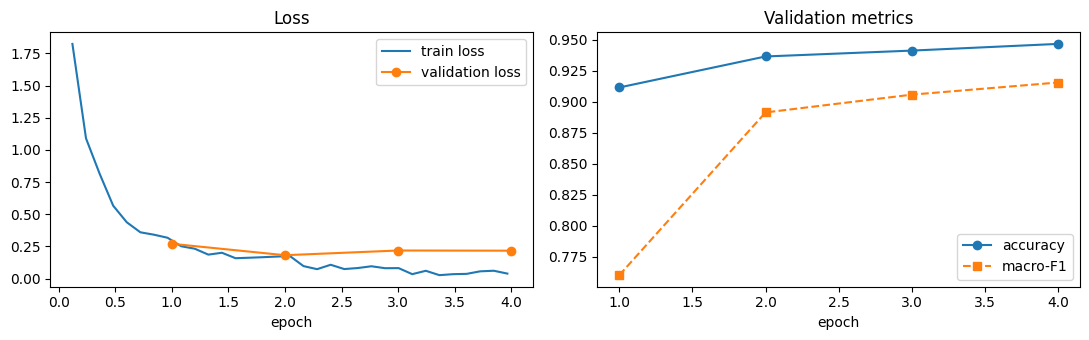

In [14]:
hist = pd.DataFrame(trainer.state.log_history)
epoch_log = hist.dropna(subset=["eval_accuracy"])[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]]
train_loss = hist.dropna(subset=["loss"])[["step", "epoch", "loss"]]
display(epoch_log.reset_index(drop=True))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(train_loss["epoch"], train_loss["loss"], label="train loss")
ax[0].plot(epoch_log["epoch"], epoch_log["eval_loss"], "o-", label="validation loss")
ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(epoch_log["epoch"], epoch_log["eval_accuracy"], "o-", label="accuracy")
ax[1].plot(epoch_log["epoch"], epoch_log["eval_macro_f1"], "s--", label="macro-F1")
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("Validation metrics")
plt.tight_layout(); plt.show()

## 7. Evaluation on the held-out test set

In [15]:
t0 = time.perf_counter()
pred_out = trainer.predict(test_ds)
test_seconds = time.perf_counter() - t0
y_true = pred_out.label_ids
y_pred = np.argmax(pred_out.predictions, axis=-1)

test_acc = accuracy_score(y_true, y_pred)
test_f1 = f1_score(y_true, y_pred, average="macro")
print(f"TEST accuracy = {test_acc:.4f} | macro-F1 = {test_f1:.4f} | "
      f"{len(y_true)} samples in {test_seconds:.1f}s ({test_seconds/len(y_true)*1000:.2f} ms/sample on {DEVICE})")
print()
print(classification_report(y_true, y_pred, target_names=EVENT_LABELS, digits=4))

TEST accuracy = 0.9338 | macro-F1 = 0.8924 | 3972 samples in 2.2s (0.54 ms/sample on cuda)

                              precision    recall  f1-score   support

         Earnings & Guidance     0.9438    0.9711    0.9572       242
      Mergers & Acquisitions     0.8829    0.8448    0.8634       116
          Regulatory & Legal     0.8482    0.8261    0.8370       115
                   Financing     0.8608    0.7907    0.8242        86
           Management Change     0.9346    0.9009    0.9174       111
Product & Business Expansion     0.8788    0.8989    0.8888       831
                       Other     0.9602    0.9575    0.9589      2471

                    accuracy                         0.9338      3972
                   macro avg     0.9013    0.8843    0.8924      3972
                weighted avg     0.9338    0.9338    0.9337      3972



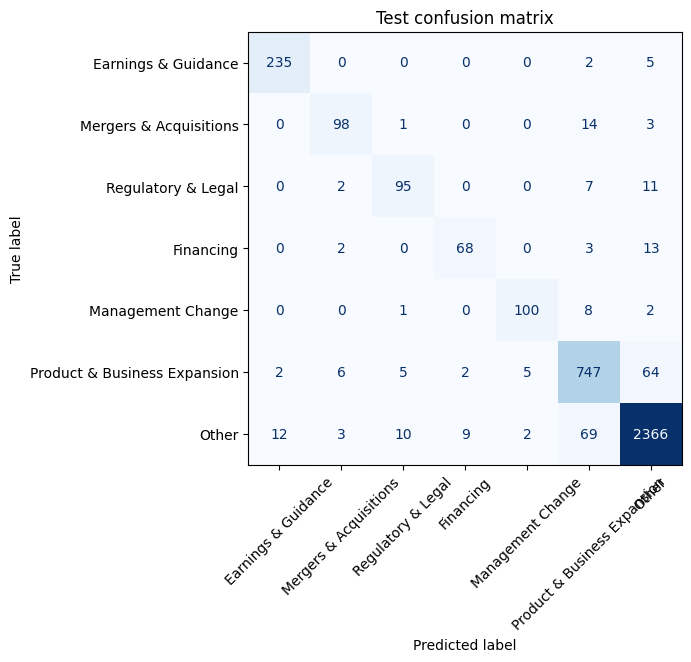

In [16]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 7) if len(EVENT_LABELS) > 3 else (4.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=EVENT_LABELS).plot(ax=ax, cmap="Blues", colorbar=False,
                                                             xticks_rotation=45)
ax.set_title("Test confusion matrix"); plt.tight_layout(); plt.show()

In [17]:
# A few misclassified test examples (error analysis)
errors = test_df.assign(predicted=[EVENT_ID2LABEL[i] for i in y_pred])
errors = errors[errors["label"] != y_pred][["text", "label_name", "predicted"]]
print(f"{len(errors)} misclassified test samples")
errors.head(10)

263 misclassified test samples


,text,label_name,predicted
13,"Rosenblatt upgrades Twitter to buy, sees heigh...",Other,Product & Business Expansion
20,Cintas Corporation Added to the FTSE4Good Index,Other,Product & Business Expansion
23,$MSFT - Microsoft Azure looks strong going int...,Other,Product & Business Expansion
40,$CHNG $UNH - Change Healthcare added to positi...,Other,Product & Business Expansion
42,$BYDDF $BYDDY - Goldman Sachs expects BYD Comp...,Other,Product & Business Expansion
60,$RIVN - Rivian Automotive target raised to $40...,Other,Product & Business Expansion
74,Citi Second Quarter 2022 Fixed Income Investor...,Product & Business Expansion,Other
86,What really happens to Amazon returns,Other,Product & Business Expansion
96,Investing Club: Alphabet's 20-for-1 stock spli...,Product & Business Expansion,Other
98,“Boeing is a far mightier aircraft manufacture...,Product & Business Expansion,Regulatory & Legal


## 8. Save, publish and package

In [18]:
# Save the best model (+ tokenizer) and a metrics file
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

metrics = {
    "base_model": BASE_MODEL, "dataset": DATASET_ID, "labels": EVENT_LABELS,
    "train_samples": len(train_df), "validation_samples": len(val_df), "test_samples": len(test_df),
    "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE, "max_len": MAX_LEN,
    "best_validation_accuracy": float(epoch_log["eval_accuracy"].max()),
    "test_accuracy": float(test_acc), "test_macro_f1": float(test_f1),
    "training_minutes": round(train_minutes, 2),
    "test_ms_per_sample": round(test_seconds / len(y_true) * 1000, 3), "device": DEVICE,
    "epoch_log": epoch_log.round(4).to_dict(orient="records"),
}
with open(os.path.join(OUTPUT_DIR, "training_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)

card_lines = [
    "---", "license: apache-2.0", f"base_model: {BASE_MODEL}", f"datasets: [{DATASET_ID}]",
    "pipeline_tag: text-classification", "language: en", "---",
    f"# {HUB_MODEL_ID}",
    f"FinSignal (ISOM5240 Group 7, for Wealthsimple). Fine-tuned from `{BASE_MODEL}` on `{DATASET_ID}`.",
    "", f"Labels: {', '.join(EVENT_LABELS)}", "",
    "| metric (held-out test) | value |", "|---|---|",
    f"| accuracy | {test_acc:.4f} |", f"| macro-F1 | {test_f1:.4f} |",
    f"| test samples | {len(test_df)} |",
]
with open(os.path.join(OUTPUT_DIR, "README.md"), "w") as f:
    f.write("\n".join(card_lines))

# Dataset files used for fine-tuning and testing (for the submission folder)
train_df.to_csv(f"{DATA_DIR}/event_train.csv", index=False)
val_df.to_csv(f"{DATA_DIR}/event_validation.csv", index=False)
test_df.to_csv(f"{DATA_DIR}/event_test.csv", index=False)
print(json.dumps({k: v for k, v in metrics.items() if k != "epoch_log"}, indent=2))

{
  "base_model": "distilbert-base-uncased",
  "dataset": "zeroshot/twitter-financial-news-topic",
  "labels": [
    "Earnings & Guidance",
    "Mergers & Acquisitions",
    "Regulatory & Legal",
    "Financing",
    "Management Change",
    "Product & Business Expansion",
    "Other"
  ],
  "train_samples": 13305,
  "validation_samples": 1479,
  "test_samples": 3972,
  "epochs": 4,
  "learning_rate": 3e-05,
  "batch_size": 32,
  "max_len": 96,
  "best_validation_accuracy": 0.9465855307640297,
  "test_accuracy": 0.9337865055387714,
  "test_macro_f1": 0.8924237469679215,
  "training_minutes": 3.23,
  "test_ms_per_sample": 0.544,
  "device": "cuda"
}


In [19]:
# Publish to Hugging Face
token = None
try:
    from google.colab import userdata
    token = userdata.get("HF_TOKEN")
except Exception as e:
    token = os.environ.get("HF_TOKEN")

if PUSH_TO_HUB and token:
    from huggingface_hub import create_repo, upload_folder
    create_repo(HUB_MODEL_ID, token=token, exist_ok=True, private=False)
    upload_folder(repo_id=HUB_MODEL_ID, folder_path=OUTPUT_DIR, token=token,
                  commit_message="FinSignal fine-tuned model")
    print("Published: https://huggingface.co/" + HUB_MODEL_ID)
else:
    print("HF_TOKEN not available -> skipped upload (model saved locally in ./" + OUTPUT_DIR + ")")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...tilbert/model.safetensors:   0%|          |  573kB /  268MB            

  ...tilbert/training_args.bin:  34%|###4      | 1.99kB / 5.84kB            

Published: https://huggingface.co/Ikenna14/finsignal-event-distilbert


In [20]:
# Sanity check: reload the saved model through a Hugging Face pipeline (exactly how the app uses it)
clf = pipeline("text-classification", model=OUTPUT_DIR, tokenizer=OUTPUT_DIR,
               device=0 if DEVICE == "cuda" else -1)
examples = ['Chipmaker agrees to acquire networking rival in $12 billion cash deal', 'Retailer beats quarterly profit estimates and raises full-year guidance', 'Federal regulators sue payments company over hidden consumer fees', 'Airline names longtime CFO as next chief executive']
for text, res in zip(examples, clf([clean_text(x) for x in examples], truncation=True, max_length=MAX_LEN)):
    print(f"{res['label']:<20} {res['score']:.3f}  {text}")

Device set to use cuda:0


Mergers & Acquisitions 0.988  Chipmaker agrees to acquire networking rival in $12 billion cash deal
Other                0.998  Retailer beats quarterly profit estimates and raises full-year guidance
Regulatory & Legal   0.992  Federal regulators sue payments company over hidden consumer fees
Management Change    0.995  Airline names longtime CFO as next chief executive


In [21]:
# Zip the model and data folders for the submission package
shutil.make_archive(OUTPUT_DIR, "zip", OUTPUT_DIR)
shutil.make_archive(f"{OUTPUT_DIR}_data", "zip", DATA_DIR)
print(os.listdir("."))
try:
    from google.colab import files
    files.download(f"{OUTPUT_DIR}.zip"); files.download(f"{OUTPUT_DIR}_data.zip")
except Exception:
    pass

['.config', 'finsignal-event-distilbert.zip', 'finsignal-event-distilbert_data.zip', 'data', 'checkpoints', 'finsignal-event-distilbert', 'sample_data']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>